In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [5]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nCSV files available:")
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


DATA_DIR = "/kaggle/input/competitions/ieee-fraud-detection"

transaction_sample = pd.read_csv(
    f"{DATA_DIR}/train_transaction.csv",
    nrows=1000
)

identity_sample = pd.read_csv(
    f"{DATA_DIR}/train_identity.csv",
    nrows=1000
)

print("Transaction:", transaction_sample.shape)
print("Identity:", identity_sample.shape)

print("\nFraud counts:")
print(transaction_sample["isFraud"].value_counts())

Python is working!
Pandas version: 2.3.3
NumPy version: 2.1.3

CSV files available:
/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv
Transaction: (1000, 394)
Identity: (1000, 41)

Fraud counts:
isFraud
0    985
1     15
Name: count, dtype: int64


In [1]:

from pathlib import Path

DATA_DIR = Path("/kaggle/input")

for path in DATA_DIR.rglob("*.csv"):
    print(path)


/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

transaction_files = list(DATA_DIR.rglob("train_transaction.csv"))
identity_files = list(DATA_DIR.rglob("train_identity.csv"))

assert transaction_files, "train_transaction.csv was not found"
assert identity_files, "train_identity.csv was not found"

transaction_path = transaction_files[0]
identity_path = identity_files[0]

start = time.time()

transactions = pd.read_csv(transaction_path, nrows=5000)
identity = pd.read_csv(identity_path, nrows=5000)

print("Transaction sample shape:", transactions.shape)
print("Identity sample shape:", identity.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")

display(transactions.head(5))


Transaction sample shape: (5000, 394)
Identity sample shape: (5000, 41)
Loading time: 0.34 seconds


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:

print("Fraud label counts:")
print(transactions["isFraud"].value_counts())

print("\nFraud label percentages:")
print(
    (transactions["isFraud"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing fraud labels:")
print(transactions["isFraud"].isna().sum())


Fraud label counts:
isFraud
0    4891
1     109
Name: count, dtype: int64

Fraud label percentages:
isFraud
0    97.82
1     2.18
Name: proportion, dtype: float64

Missing fraud labels:
0


In [5]:

print("TransactionDT summary:")
print(transactions["TransactionDT"].describe())

print("\nFirst 10 transaction times:")
print(transactions["TransactionDT"].head(10).to_list())

print(
    "\nAre the first 5,000 rows sorted by TransactionDT?",
    transactions["TransactionDT"].is_monotonic_increasing
)


TransactionDT summary:
count      5000.000000
mean     139599.938800
std       24886.671042
min       86400.000000
25%      129170.500000
50%      146625.500000
75%      158543.750000
max      171642.000000
Name: TransactionDT, dtype: float64

First 10 transaction times:
[86400, 86401, 86469, 86499, 86506, 86510, 86522, 86529, 86535, 86536]

Are the first 5,000 rows sorted by TransactionDT? True


# Dataset Audit — Initial Sample

## Purpose
Verify dataset access and understand the basic structure of the IEEE-CIS Fraud Detection dataset.

## Files
- Transaction file: confirmed
- Identity file: confirmed

## Initial sample
- Transaction sample rows: 5,000
- Transaction columns: 394
- Identity sample rows: 5,000
- Identity columns: 41
- Loading time: 0.34 seconds

## Fraud label
- Non-fraud transactions: 4,891
- Fraud transactions: 109
- Fraud percentage in this sample: 2.18%
- Missing fraud labels: 0

## Time variable
- TransactionDT minimum: 86,400
- TransactionDT maximum: 171,642
- Rows sorted by TransactionDT: yes

## Initial interpretation
The sample contains substantially more non-fraud transactions than fraudulent transactions. This is a class-imbalanced classification problem. TransactionDT increases across the first 5,000 rows, which supports investigating chronological evaluation.

## Limitations
These results describe only the first 5,000 transaction rows. The observed fraud rate is not necessarily representative of the complete dataset. The sorted sample does not establish that every row in the full dataset is sorted, nor does it prove concept drift.

## Next step
Audit the complete transaction dataset and examine its time coverage, missing values, and fraud distribution.

In [2]:

from pathlib import Path
import time
import pandas as pd
import numpy as np

# Find the training transaction file again
matches = list(
    Path("/kaggle/input").rglob("train_transaction.csv")
)

if not matches:
    raise FileNotFoundError(
        "Could not find train_transaction.csv. Check Kaggle's Input panel."
    )

transaction_path = matches[0]
print("Using file:", transaction_path)

# Load only the columns needed for this audit
audit_columns = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD"
]

start = time.time()

audit_df = pd.read_csv(
    transaction_path,
    usecols=audit_columns
)

print("\nFull transaction audit shape:", audit_df.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")

print("\nMissing values:")
print(audit_df.isna().sum())

print("\nDuplicate TransactionIDs:")
print(audit_df["TransactionID"].duplicated().sum())

print("\nFraud counts:")
print(audit_df["isFraud"].value_counts())

print("\nFraud percentages:")
print(
    (audit_df["isFraud"].value_counts(normalize=True) * 100).round(3)
)

print("\nTransactionDT range:")
print("Minimum:", audit_df["TransactionDT"].min())
print("Maximum:", audit_df["TransactionDT"].max())

print(
    "\nEntire dataset sorted by TransactionDT:",
    audit_df["TransactionDT"].is_monotonic_increasing
)


Using file: /kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv

Full transaction audit shape: (590540, 5)
Loading time: 8.7 seconds

Missing values:
TransactionID     0
isFraud           0
TransactionDT     0
TransactionAmt    0
ProductCD         0
dtype: int64

Duplicate TransactionIDs:
0

Fraud counts:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentages:
isFraud
0    96.501
1     3.499
Name: proportion, dtype: float64

TransactionDT range:
Minimum: 86400
Maximum: 15811131

Entire dataset sorted by TransactionDT: True


,transactions,fraud_cases,start_time,end_time,fraud_rate_percent
time_window,,,,,
Window 1,118108,2826,86400,2310138,2.393
Window 2,118108,4732,2310165,5592303,4.007
Window 3,118108,4430,5592304,8745772,3.751
Window 4,118108,4611,8745798,12192842,3.904
Window 5,118108,4064,12192900,15811131,3.441


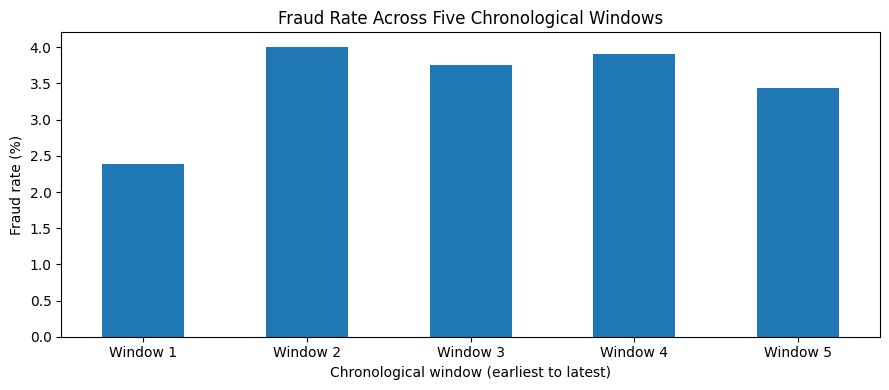

In [13]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Sort transactions by time and reset the row index
time_df = audit_df.sort_values("TransactionDT").reset_index(drop=True).copy()

# Divide the ordered rows into five consecutive windows
n = len(time_df)
window_number = np.minimum(np.arange(n) * 5 // n, 4)

window_labels = [
    "Window 1", "Window 2", "Window 3", "Window 4", "Window 5"
]

time_df["time_window"] = [
    window_labels[i] for i in window_number
]

# Calculate fraud statistics for each window
temporal_summary = (
    time_df.groupby("time_window", sort=False)
    .agg(
        transactions=("isFraud", "size"),
        fraud_cases=("isFraud", "sum"),
        start_time=("TransactionDT", "min"),
        end_time=("TransactionDT", "max")
    )
)

temporal_summary["fraud_rate_percent"] = (
    temporal_summary["fraud_cases"]
    / temporal_summary["transactions"] * 100
)

display(temporal_summary.round(3))

# Plot the fraud rate over time
ax = temporal_summary["fraud_rate_percent"].plot(
    kind="bar",
    figsize=(9, 4),
    title="Fraud Rate Across Five Chronological Windows"
)

ax.set_xlabel("Chronological window (earliest to latest)")
ax.set_ylabel("Fraud rate (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()



### Results

The complete training transaction dataset contains 590,540 transactions, divided into five chronological windows of 118,108 transactions each.

The observed fraud rates were:

- Window 1: 2.393%
- Window 2: 4.007%
- Window 3: 3.751%
- Window 4: 3.904%
- Window 5: 3.441%

The highest rate occurred in Window 2 and the lowest in Window 1. The difference was 1.614 percentage points.

### Interpretation

Fraud prevalence varies across the five chronological windows. This motivates further investigation of temporal changes in transaction features and predictive performance.

These descriptive results alone do not establish concept drift or statistical significance.

### Next step

Measure missingness across the transaction features and determine how much of the transaction dataset has matching identity information.

In [14]:

from collections import Counter

# Count missing values in each column, reading 50,000 rows at a time
missing_counts = Counter()
total_rows = 0

start = time.time()

for chunk in pd.read_csv(
    transaction_path,
    chunksize=50000
):
    missing_counts.update(chunk.isna().sum().to_dict())
    total_rows += len(chunk)

missing_summary = pd.DataFrame({
    "missing_count": pd.Series(missing_counts),
    "missing_percent": pd.Series(missing_counts) / total_rows * 100
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

print("Rows examined:", total_rows)
print("Columns examined:", len(missing_summary))
print("Time taken:", round(time.time() - start, 2), "seconds")

print("\nTop 20 columns with the most missing values:")
display(missing_summary.head(20).round(2))

print(
    "\nColumns with no missing values:",
    (missing_summary["missing_count"] == 0).sum()
)

print(
    "Columns with more than 50% missing:",
    (missing_summary["missing_percent"] > 50).sum()
)


Rows examined: 590540
Columns examined: 394
Time taken: 18.35 seconds

Top 20 columns with the most missing values:


,missing_count,missing_percent
dist2,552913,93.63
D7,551623,93.41
D13,528588,89.51
D14,528353,89.47
D12,525823,89.04
D6,517353,87.61
D9,515614,87.31
D8,515614,87.31
V153,508595,86.12
V149,508595,86.12



Columns with no missing values: 20
Columns with more than 50% missing: 174


## Missing-Value Audit

**Method:** Processed the complete transaction CSV in chunks of 50,000 rows and counted missing values across all columns.

**Results:**
- Transactions examined: 590,540
- Columns examined: 394
- Columns with no missing values: 20
- Columns with more than 50% missing values: 174
- Processing time: approximately 20.22 seconds

**Examples of highly incomplete features:**
- dist2: 93.63% missing
- D7: 93.41% missing
- D13: 89.51% missing
- D14: 89.47% missing

**Interpretation:** Missingness is widespread and may affect feature selection, preprocessing, and temporal robustness. Highly incomplete features should be investigated rather than automatically discarded.

**Limitation:** This audit measures overall missingness. It does not establish why values are missing, whether missingness differs between fraud and non-fraud transactions, or whether missingness changes over time.

**Next step:** Determine identity-table coverage and investigate how transaction and identity records are linked.

In [3]:

from pathlib import Path
import pandas as pd

# Find the identity CSV again, in case the session was restarted
identity_files = list(
    Path("/kaggle/input").rglob("train_identity.csv")
)

assert identity_files, "train_identity.csv was not found"

identity_path = identity_files[0]

# Read only transaction IDs from both files
transaction_ids = pd.read_csv(
    transaction_path,
    usecols=["TransactionID"]
)

identity_ids = pd.read_csv(
    identity_path,
    usecols=["TransactionID"]
)

transaction_id_set = set(transaction_ids["TransactionID"])
identity_id_set = set(identity_ids["TransactionID"])

matched_count = len(transaction_id_set & identity_id_set)
unmatched_count = len(transaction_id_set - identity_id_set)

print("Transactions:", len(transaction_id_set))
print("Identity records:", len(identity_id_set))
print("Transactions with identity records:", matched_count)
print("Transactions without identity records:", unmatched_count)

print(
    "Identity coverage (%):",
    round(matched_count / len(transaction_id_set) * 100, 2)
)

print(
    "Transactions without identity (%):",
    round(unmatched_count / len(transaction_id_set) * 100, 2)
)

print(
    "Duplicate IDs in identity table:",
    identity_ids["TransactionID"].duplicated().sum()
)


Transactions: 590540
Identity records: 144233
Transactions with identity records: 144233
Transactions without identity records: 446307
Identity coverage (%): 24.42
Transactions without identity (%): 75.58
Duplicate IDs in identity table: 0


In [5]:

# Mark whether each transaction has a matching identity record
has_identity = audit_df["TransactionID"].isin(
    identity_ids["TransactionID"]
)

# Calculate fraud statistics for the two groups
identity_analysis = audit_df.assign(
    has_identity=has_identity
).groupby("has_identity").agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum")
)

identity_analysis["fraud_rate_percent"] = (
    identity_analysis["fraud_cases"]
    / identity_analysis["transactions"] * 100
)

identity_analysis.index = identity_analysis.index.map({
    True: "Identity available",
    False: "Identity unavailable"
})

display(identity_analysis.round(3))


,transactions,fraud_cases,fraud_rate_percent
has_identity,,,
Identity unavailable,446307,9345,2.094
Identity available,144233,11318,7.847
